# Data 620 Week 5 Assignment - Project 1
### Author: Pedro P Gatica Jr

## Introduction: 
#### Do the most influential political blogs reach across the aisle, or do they mainly strengthen their own side? To find out, this project uses a set of blogs from the 2004 election, each labeled liberal or conservative, and compares five different ways of measuring a blog's importance to see how they connect to its political leaning.
## Source: 
#### I am analyzing Adamic, L. A. & Glance, N. (2005), "The Political Blogosphere and the 2004 U.S. Election: Divided They Blog," Proc. 3rd Int'l Workshop on Link Discovery
## Format: 
#### GML (also available as GraphML/CSV mirrors)
## Access method:
#### Direct download (static file), no scraping or API needed

In [1]:
import os
import io
import zipfile
import urllib.request
import re

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

sns.set_theme(style="whitegrid")

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
# ---------------------------------------------------------------------------
# 1. DOWNLOAD & LOAD THE DATA
# ---------------------------------------------------------------------------
DATA_DIR = "https://github.com/audiorunner13/Masters-Coursework/tree/main/Data620%20Fall%202026/Week%205/Project%201/polblogs_data"
GML_PATH = os.path.join(DATA_DIR, "polblogs.gml")
# Canonical source (Newman's data page). If this mirror ever goes down,
# an identical file is available at https://networks.skewed.de/net/polblogs
# (download the GML there and point GML_PATH at it).
SOURCE_URL = "http://www-personal.umich.edu/~mejn/netdata/polblogs.zip"

print(DATA_DIR)
print(GML_PATH)
print(SOURCE_URL)

https://github.com/audiorunner13/Masters-Coursework/tree/main/Data620%20Fall%202026/Week%205/Project%201/polblogs_data
https://github.com/audiorunner13/Masters-Coursework/tree/main/Data620%20Fall%202026/Week%205/Project%201/polblogs_data/polblogs.gml
http://www-personal.umich.edu/~mejn/netdata/polblogs.zip


In [3]:
print(f"Downloading from {SOURCE_URL} ...")
req = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as resp:
    data = resp.read()
with zipfile.ZipFile(io.BytesIO(data)) as z:
    z.extractall(DATA_DIR)
print("Done ->", GML_PATH)

Done -> https://github.com/audiorunner13/Masters-Coursework/tree/main/Data620%20Fall%202026/Week%205/Project%201/polblogs_data/polblogs.gml


In [4]:
with open(GML_PATH, "r", encoding="utf-8", errors="ignore") as f:
    text = f.read()

# Tell NetworkX the file may contain parallel edges
if "multigraph" not in text:
    text = re.sub(r"graph\s*\[", "graph [\n  multigraph 1", text, count=1)

# The GML has multi-edges; read as MultiDiGraph then simplify to DiGraph
G_multi = nx.parse_gml(text)
G = nx.DiGraph(G_multi)  # collapse parallel edges
# Keep only the largest weakly connected component so that closeness/
# eigenvector centrality are well-defined for every remaining node.
largest_wcc = max(nx.weakly_connected_components(G), key=len)
G = G.subgraph(largest_wcc).copy()
print(f"Graph loaded: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges "
       f"(largest weakly connected component)")

Graph loaded: 1222 nodes, 19024 edges (largest weakly connected component)


#### Compute centrality measures.

In [5]:
"""Return a DataFrame indexed by node with one column per centrality measure, plus the categorical 'leaning' label."""

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
total_deg = dict(G.degree())

betweenness = nx.betweenness_centrality(G, normalized=True)
closeness = nx.closeness_centrality(G)  # uses in-distances on DiGraph
try:
    eigenvector = nx.eigenvector_centrality(G, max_iter=1000)
except nx.PowerIterationFailedConvergence:
    eigenvector = nx.eigenvector_centrality_numpy(G)
pagerank = nx.pagerank(G, alpha=0.85)

df = pd.DataFrame({
    "in_degree": pd.Series(in_deg),
    "out_degree": pd.Series(out_deg),
    "total_degree": pd.Series(total_deg),
    "betweenness": pd.Series(betweenness),
    "closeness": pd.Series(closeness),
    "eigenvector": pd.Series(eigenvector),
    "pagerank": pd.Series(pagerank),
})

leaning_raw = nx.get_node_attributes(G, "value")
df["leaning_code"] = pd.Series(leaning_raw)
df["leaning"] = df["leaning_code"].map({0: "liberal", 1: "conservative"})

# Blog name / label, handy for eyeballing top nodes
if nx.get_node_attributes(G, "label"):
    df["label"] = pd.Series(nx.get_node_attributes(G, "label"))

df.dropna(subset=["leaning"])        

,in_degree,out_degree,total_degree,betweenness,closeness,eigenvector,pagerank,leaning_code,leaning
100monkeystyping.com,12,15,27,0.000070,0.254153,5.778248e-03,0.000360,0,liberal
12thharmonic.com/wordpress,5,43,48,0.001135,0.207938,5.209745e-04,0.000359,0,liberal
750volts.blogspot.com,1,3,4,0.000692,0.183110,2.943279e-05,0.000265,0,liberal
95theses.blogspot.com,0,1,1,0.000000,0.000000,7.361895e-55,0.000197,0,liberal
abbadabbaduo.blogspot.com,1,0,1,0.000000,0.221199,1.347272e-03,0.000207,0,liberal
...,...,...,...,...,...,...,...,...,...
youngconservative.blogspot.com,2,1,3,0.000006,0.247631,6.525263e-04,0.000257,1,conservative
zebrax.blogs.com,4,15,19,0.000284,0.213734,2.022385e-04,0.000268,1,conservative
zeke01.blogspot.com,0,1,1,0.000000,0.000000,7.361895e-55,0.000197,1,conservative
zeke01.typepad.com,14,8,22,0.001379,0.260712,1.419806e-03,0.000870,1,conservative


### What stands out in the rows:

##### The top five blogs are all liberal, and the bottom five are all conservative. The reason for this is the list is sorted alphabetically and this is a preview, so it really does not tell us anything about the groups yet.

#### zeke01.typepad.com is the strongest blog shown. It has the most incoming links (14), the highest betweenness (0.001379), the highest closeness (0.2607), and by far the highest PageRank (0.000870). It's both popular and well placed in the network.

#### 12thharmonic.com/wordpress has a lot of outgoing links (43) but few incoming (5). It points to many others but isn't linked to much, so it's more of a "sharer" than an authority. It still has decent betweenness (0.001135), suggesting it helps link different parts of the network.  It also leans conservative.

#### 100monkeytyping.com is moderately connected in both directions and has a fairly high closeness (0.254), which one can read as being reasonably central.

### Compute the averages and p_val of the centrality measures
#### The p-value asks whether the difference between the two groups is real or could just be chance. A p-value below about 0.05 is usually treated as a real difference.

In [6]:
measures = ["in_degree", "out_degree", "betweenness",
                "closeness", "eigenvector", "pagerank"]

In [7]:
 print("\n=== Group comparison: liberal vs. conservative ===")
summary_rows = []
for m in measures:
    lib = df.loc[df.leaning == "liberal", m]
    con = df.loc[df.leaning == "conservative", m]
    t_stat, p_val = stats.mannwhitneyu(lib, con, alternative="two-sided")
    summary_rows.append({
        "Measure": m,
        "Liberal Average": lib.mean(),
        "Conservative Average": con.mean(),
        "p_value": p_val,
    })
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))


=== Group comparison: liberal vs. conservative ===
    Measure  Liberal Average  Conservative Average      p_value
  in_degree        15.849829             15.308176 1.424101e-02
 out_degree        15.643345             15.498428 1.844955e-01
betweenness         0.001358              0.001224 8.370247e-02
  closeness         0.183666              0.218605 3.115001e-09
eigenvector         0.017585              0.004261 2.102858e-02
   pagerank         0.000825              0.000813 1.069927e-04


#### In-Degree and Out-Degree averages are about the same. The small in-degree difference is detectable but not meaningful.  While the Out-degree differennce is slightly larger than In-Degree it is also nnot meanningful.
#### Betweenness is very similar which can meant that neither liberals or conservatives as act as a "bridge" more than the other.
#### Conservative blogs have higher closeness which is a very clear difference. Conservative blogs can reach the rest of the network in fewer node steps, which suggests their links are more tightly interconnected. Liberal blogs appear to have more blog with zero closeness, which pull their average down.
#### The Liberal blogs have about 4 times the eigenvector score which can mean that these tend to be connected to other well connected and influential blogs.
#### These averages are also shown on the bo plots of the entire network dataset.

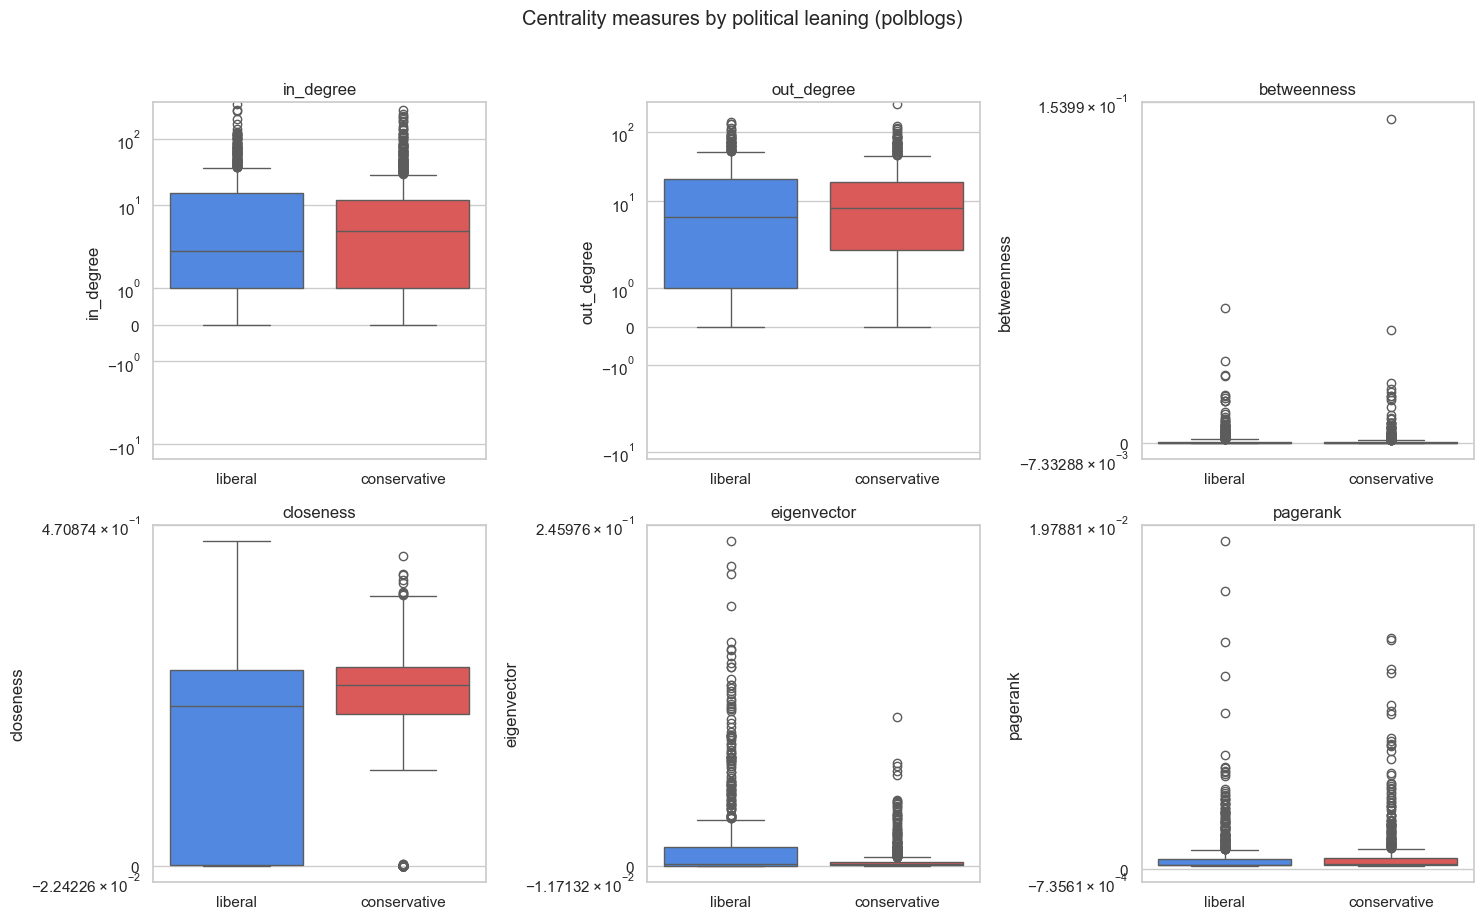

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, m in zip(axes.flat, measures):
    sns.boxplot(data=df, x="leaning", y=m, hue="leaning",
                palette={"liberal": "#3b82f6", "conservative": "#ef4444"},
                legend=False, ax=ax)
    ax.set_yscale("symlog")  # centrality distributions are heavy-tailed
    ax.set_title(m)
    ax.set_xlabel("")
for ax in axes.flat[len(measures):]:
    ax.axis("off")
fig.suptitle("Centrality measures by political leaning (polblogs)", y=1.02)
fig.tight_layout()

## Get the Top 50 Pagerank Blogs

In [9]:
n=50
measure="pagerank"
print(f"\nTop {n} blogs by {measure}:")
cols = [c for c in ["label", "leaning", measure] if c in df.columns]
print(df.sort_values(measure, ascending=False)[cols].head(n).to_string(index=False))



Top 50 blogs by pagerank:
     leaning  pagerank
     liberal  0.018855
     liberal  0.015995
conservative  0.013290
conservative  0.013152
     liberal  0.013060
conservative  0.011488
conservative  0.011269
     liberal  0.011079
conservative  0.009406
conservative  0.009061
     liberal  0.008945
conservative  0.008929
conservative  0.007558
conservative  0.007370
conservative  0.007187
conservative  0.007110
conservative  0.007053
conservative  0.006783
     liberal  0.006544
conservative  0.006346
     liberal  0.005848
     liberal  0.005783
     liberal  0.005648
     liberal  0.005597
conservative  0.005534
     liberal  0.005440
conservative  0.005417
     liberal  0.005329
conservative  0.004961
conservative  0.004881
conservative  0.004787
conservative  0.004652
     liberal  0.004628
conservative  0.004607
     liberal  0.004460
conservative  0.004445
     liberal  0.004365
conservative  0.004314
     liberal  0.004268
     liberal  0.004188
conservative  0.004163
conserv

#### There are 28 Conservative blogs and 22 Liberal blogs in the top 50 Pagerank
#### The Conservative and Liberal leans are close to even at 56% to 44%.  With Conservatives being more in the top 20 (14 of 20) but then on 14 of the next 30.
#### Three of the top 11 Pagerank blogs are liberal which matches the box plot that shows Liberal blogs with the highest outliers.
#### The Pagerank scores fall from 0.0189 at the highest to 0.0038 at the 50th spot which means that only a small numnber of blogs at the top hold the greatest influence

## Get to the Top 50 Betweenness Blogs

In [10]:
n=50
measure="betweenness"
print(f"\nTop {n} blogs by {measure}:")
cols = [c for c in ["label", "leaning", measure] if c in df.columns]
print(df.sort_values(measure, ascending=False)[cols].head(n).to_string(index=False))


Top 50 blogs by betweenness:
     leaning  betweenness
conservative     0.146658
     liberal     0.061080
conservative     0.051201
     liberal     0.036910
     liberal     0.030810
     liberal     0.030224
conservative     0.027257
conservative     0.024258
conservative     0.022992
     liberal     0.021925
     liberal     0.021333
conservative     0.021087
conservative     0.021078
conservative     0.020286
     liberal     0.020226
conservative     0.019444
     liberal     0.019065
     liberal     0.018976
     liberal     0.018971
conservative     0.016398
     liberal     0.013933
     liberal     0.013289
conservative     0.012725
     liberal     0.011603
conservative     0.011350
     liberal     0.011049
     liberal     0.011007
conservative     0.010829
     liberal     0.010132
     liberal     0.009772
     liberal     0.009659
     liberal     0.009489
conservative     0.009267
conservative     0.009138
conservative     0.009027
conservative     0.008921
     lib

#### There are 19 Conservative blogs and 31 Liberal blogs in the top 50 for Betweennness
#### The very top betweenness rank is a conservative blog at 0.147. This is more than twice the next blog (a liberal one at 0.061). This is the outlier we see in the box plot. This blog does an unusually large share of the bridging.
#### Notice that the Top 20 is evenly split at 10 blogs for each side which means that neither one owns the highest-bridging spots.
#### Liberal Blogs make up the bottom 30 at 21 to 9 Conservative.
#### Betweenness scores fall from 0.147 to about 0.007 for the top 50 so a small numner of blogs do the bridging to the rest of the network.

## Run a predictive model to determine that if one knows the centrality scores, could one predict whether a blog is Liberal or Conservative.

In [11]:
print("\n=== Predicting leaning from centrality measures (logistic regression) ===")
X = df[measures].values
y = (df["leaning"] == "conservative").astype(int).values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["liberal", "conservative"]))
print(f"Test Area Under Curve: {roc_auc_score(y_test, y_prob):.3f}")

cv_scores = cross_val_score(clf, X_scaled, y, cv=5, scoring="roc_auc")
print(f"5-fold Cross Value Area Under Curve: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

coefs = pd.Series(clf.coef_[0], index=measures).sort_values(key=abs, ascending=False)
print("\nStandardized coefficients (which centrality measures matter most):")
print(coefs.to_string())




=== Predicting leaning from centrality measures (logistic regression) ===
              precision    recall  f1-score   support

     liberal       0.77      0.67      0.72       147
conservative       0.73      0.81      0.77       159

    accuracy                           0.75       306
   macro avg       0.75      0.74      0.74       306
weighted avg       0.75      0.75      0.74       306

Test Area Under Curve: 0.837
5-fold Cross Value Area Under Curve: 0.849 (+/- 0.019)

Standardized coefficients (which centrality measures matter most):
eigenvector   -5.672366
in_degree      2.149656
pagerank       1.963974
betweenness   -1.008311
closeness      0.569532
out_degree     0.245281


#### The model was trained on 306 random blogs and the results are as follows.
#### Accuracy score is 75%. The test set is 159 of 306 Conservaative or around 52%. While it is better than guessing it is not highly accurate.
#### The AUC(Area Under Curve) is 0.837.  This measures how well the model ranks liberal to conservative blogs this measure is very good. The measure should fall between 0.5 to 1.0.
#### The 5-fold cross value AUC test is 0.849 which is close to the 0.837 originally calculated. This was a test run 5 additional times on random sets of 306. This is an accurate test.
### What do the coeeficients reveal?
#### - eigenvector pushes toward Liberal
#### - in degree pushes toward Conservative
#### - pagerank pushes toward Conservative
#### - betweenness pushes toward Liberal
#### - closeness pushes weakly towards Conservative
#### - out degree is nuetral

## In Conclusion
### Just by looking at where a blog sits in the web of links (and nothing about what it actually says), the model could guess a blog's political side correctly about 3 out of 4 times.That fits what we saw earlier: liberal and conservative blogs get and give about the same number of links, but they differ in how tightly connected they are to the rest of the network and in who links to them.
### Since accuracy is only 75%, this means that 25% of the blogs are incorrectly classified so neither owns the most central nodes.